# Init

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

from spectraderma_processor import SpectraDermaProcessor

mpl.rcParams['font.family'] = 'arial'
mpl.rcParams['font.size'] = 10

colors = [
    '#8686D2',
    '#7BAED3',
    '#9CCBA0',
    '#E6DC84',
    '#D47291',
    '#868686',
]

In [2]:
# Initialize processor
processor = SpectraDermaProcessor(sample_rate=50.0)

In [3]:
# Subject data definitions
subjects = {
    '555S2': {
        'file': '../data/spectraderama_data_2025-04-02_sattac555S2.csv',
        'regions': [(1500, 4500), (386600, 389600)],
        'denoise_params': {'wavelet': 'db2', 'level': 3, 'zero_levels': (1, 2, 3)},
        'filter_params': {'low_freq': 0.5, 'high_freq': 2.5, 'order': 3}
    },
    '520S2': {
        'file': '../data/spectraderama_data_2025-03-25_sattac520S2.csv',
        'regions': [(500, 2500), (423000, 425000)],
        'denoise_params': {'wavelet': 'db2', 'level': 2, 'zero_levels': (1, 2)},
        'filter_params': {'low_freq': 0.5, 'high_freq': 3.0, 'order': 3}
    },
    '555S1': {
        'file': '../data/spectraderama_data_2025-03-26_sattac555S1.csv',
        'regions': [(400, 3400), (338700, 341500)],
        'denoise_params': {'wavelet': 'db2', 'level': 3, 'zero_levels': (1, 2, 3)},
        'filter_params': {'low_freq': 0.5, 'high_freq': 3.0, 'order': 3}
    }
}

# SNR

In [4]:
# Initialize SNR matrix (6 regions x 6 channels)
snr_matrix = np.zeros((6, 6))
region_labels = []

print("SNR Analysis for All Subjects and Regions")
print("=" * 60)

region_idx = 0
for subject_name, subject_data in subjects.items():
    print(f"\nProcessing {subject_name}...")
    
    # Load and process data once per subject
    processor_temp = SpectraDermaProcessor(sample_rate=50.0)
    processor_temp.load_data(subject_data['file'])
    
    # Get clean reference (AC + DC)
    processor_temp.swt_denoise(**subject_data['denoise_params']).bandpass_filter(**subject_data['filter_params'])
    _, channels_ac = processor_temp.get_data()
    
    processor_temp.reset()
    processor_temp.swt_denoise(**subject_data['denoise_params']).lowpass_filter(cutoff=0.2, order=3)
    _, channels_dc = processor_temp.get_data()
    
    clean_reference = channels_ac + channels_dc
    
    # Process both regions for this subject
    for region_num, (start, end) in enumerate(subject_data['regions']):
        region_name = f"{subject_name}_R{region_num+1}"
        region_labels.append(region_name)
        
        print(f"  Region {region_num+1}: samples {start}-{end}")
        
        # Get denoised output
        processor_temp.reset()
        denoised_data = processor_temp.swt_denoise(**subject_data['denoise_params']).get_data()[1]
        
        # Extract region data
        denoised_region = denoised_data[start:end, :]
        clean_region = clean_reference[start:end, :]
        noise_region = denoised_region - clean_region
        
        # Calculate SNR for each channel
        p_signal = np.var(clean_region, axis=0)
        p_noise = np.var(noise_region, axis=0)
        snr_db = 10 * np.log10(p_signal / (p_noise + 1e-10))
        
        snr_matrix[region_idx, :] = snr_db
        
        print(f"    SNR (dB): {snr_db}")
        
        region_idx += 1

print("\n" + "=" * 60)
print("COMPLETE SNR MATRIX (6 regions x 6 channels)")
print("=" * 60)

# Create DataFrame for better visualization
wavelengths = ['415nm', '480nm', '555nm', '590nm', '680nm', '910nm']
snr_df = pd.DataFrame(snr_matrix, 
                     index=region_labels, 
                     columns=wavelengths)

print(snr_df.round(2))

print(f"\nOverall Statistics:")
print(f"Mean SNR across all regions/channels: {np.mean(snr_matrix):.2f} dB")
print(f"Std SNR across all regions/channels: {np.std(snr_matrix):.2f} dB")
print(f"Min SNR: {np.min(snr_matrix):.2f} dB")
print(f"Max SNR: {np.max(snr_matrix):.2f} dB")

SNR Analysis for All Subjects and Regions

Processing 555S2...
  Region 1: samples 1500-4500
    SNR (dB): [16.54893098 17.62867566 17.63617839 17.20301938 16.08283537 17.98604583]
  Region 2: samples 386600-389600
    SNR (dB): [10.60741444 10.26878767 11.03182683 13.04746139  6.24578     9.95255063]

Processing 520S2...
  Region 1: samples 500-2500
    SNR (dB): [2.94002487 4.47230462 9.03620743 6.53120225 1.67876834 0.01144147]
  Region 2: samples 423000-425000
    SNR (dB): [11.92392177 12.84265639 14.63019477 12.4693243  11.02588741 11.70625601]

Processing 555S1...
  Region 1: samples 400-3400
    SNR (dB): [16.72036871 11.90452381 16.13088375 19.3365729  11.72056717 17.84091246]
  Region 2: samples 338700-341500
    SNR (dB): [10.84928113  7.67178742  9.35592909 10.81933592 11.64247217 11.74619019]

COMPLETE SNR MATRIX (6 regions x 6 channels)
          415nm  480nm  555nm  590nm  680nm  910nm
555S2_R1  16.55  17.63  17.64  17.20  16.08  17.99
555S2_R2  10.61  10.27  11.03  13.0

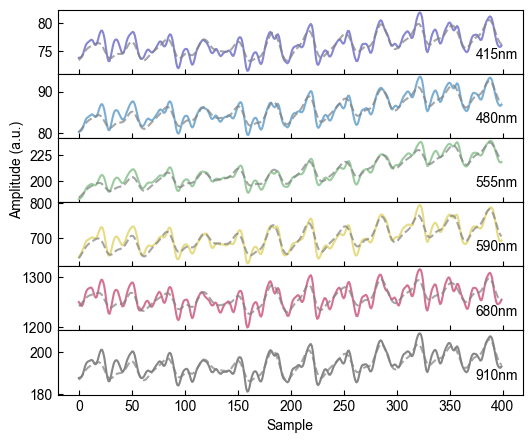


520S2_R2 SNR Analysis:
415nm: 11.92 dB
480nm: 12.84 dB
555nm: 14.63 dB
590nm: 12.47 dB
680nm: 11.03 dB
910nm: 11.71 dB
Mean SNR: 12.43 dB


In [5]:
# Example comparison: 520S2_R2 denoised vs clean data
# Use the processed data from the SNR analysis for 520S2

# Load 520S2 data and process it
processor_example = SpectraDermaProcessor(sample_rate=50.0)
processor_example.load_data('../data/spectraderama_data_2025-03-25_sattac520S2.csv')

# Get clean reference (AC + DC components)
processor_example.swt_denoise(wavelet="db2", level=2, zero_levels=(1, 2)).bandpass_filter(low_freq=0.5, high_freq=3.0, order=3)
_, channels_ac_ex = processor_example.get_data()

processor_example.reset()
processor_example.swt_denoise(wavelet="db2", level=2, zero_levels=(1, 2)).lowpass_filter(cutoff=0.2, order=3)
_, channels_dc_ex = processor_example.get_data()

clean_reference_ex = channels_ac_ex + channels_dc_ex

# Get denoised output
processor_example.reset()
denoised_data_ex = processor_example.swt_denoise(wavelet="db2", level=2, zero_levels=(1, 2)).get_data()[1]

# Extract 520S2_R2 region (423000:425000)
region_start, region_end = 423000, 425000
denoised_region = denoised_data_ex[region_start:region_end, :]
clean_region = clean_reference_ex[region_start:region_end, :]

# Plot comparison - showing 400 samples for clarity
sample_start = 100
sample_end = 500
sample_range = slice(sample_start, sample_end)

fig, axes = plt.subplots(6, 1, figsize=(6, 5), sharex=True)
fig.subplots_adjust(hspace=0.)
wavelengths = ['415nm', '480nm', '555nm', '590nm', '680nm', '910nm']

for ch in range(6):
    ax = axes[ch]
    
    ax.plot(denoised_region[sample_range, ch], label='Denoised Output', 
            color=colors[ch], linewidth=1.5)
    ax.plot(clean_region[sample_range, ch], label='Reference (Clean)', 
            color='gray', alpha=0.7, linewidth=1.5, linestyle='--')
    
    # Add wavelength label on the right
    ax.text(0.99, 0.3, wavelengths[ch], transform=ax.transAxes, 
            ha='right', va='center', fontsize=10)
    
    ax.tick_params(direction='in')
    
    if ch != 2:  # Only show y-label for the middle subplot (channel 2, 555nm)
        ax.set_ylabel('')
    else:
        ax.set_ylabel('Amplitude (a.u.)')
    
    if ch != 5:  # Remove x-labels from all but the bottom subplot
        ax.set_xlabel('')
    else:
        ax.set_xlabel('Sample')

pos_ax0 = axes[0].get_position()
pos_ax5 = axes[5].get_position()
# plt.savefig('../figures/SI/snr/snr_comparison_520S2_R2.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

# Calculate and display SNR for this specific region
noise_region = denoised_region - clean_region
p_signal = np.var(clean_region, axis=0)
p_noise = np.var(noise_region, axis=0)
snr_example = 10 * np.log10(p_signal / (p_noise + 1e-10))

print(f"\n520S2_R2 SNR Analysis:")
print("=" * 40)
for ch, wl in enumerate(wavelengths):
    print(f"{wl}: {snr_example[ch]:.2f} dB")
print(f"Mean SNR: {np.mean(snr_example):.2f} dB")

In [6]:
from matplotlib.transforms import Bbox
pos_ax = Bbox.from_extents(pos_ax0.x0, pos_ax5.y0, pos_ax0.x1, pos_ax0.y1)

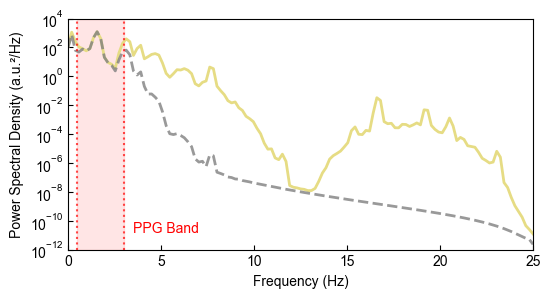

Frequency Domain Analysis - 520S2_R2, Channel 3 (590nm):
Clean Signal - Frequency SNR: 4.2 dB
Denoised Signal - Frequency SNR: 0.6 dB
PPG Power Preservation: 105.7%
Noise Reduction: -137.8%


In [7]:
from scipy.signal import welch

# Extract channel 3 (590nm) data from previous SNR analysis
channel_idx = 3
denoised_ch3 = denoised_region[:, channel_idx]
clean_ch3 = clean_region[:, channel_idx]

# Calculate Power Spectral Density using Welch's method
sample_rate = 50.0  # Hz
nperseg = 256  # Window length for Welch's method

freqs_denoised, psd_denoised = welch(denoised_ch3, fs=sample_rate, nperseg=nperseg)
freqs_clean, psd_clean = welch(clean_ch3, fs=sample_rate, nperseg=nperseg)

# Create PSD comparison plot
fig, ax = plt.subplots(figsize=(6, 3))

ax.semilogy(freqs_denoised, psd_denoised, label='Denoised Signal', 
            color=colors[3], linewidth=2)
ax.semilogy(freqs_clean, psd_clean, label='Clean Reference', 
            color='gray', linestyle='--', linewidth=2, alpha=0.8)
ax.set_ylim(1e-12, 1e4)

# Add PPG frequency band highlighting
ax.axvline(x=0.5, color='red', linestyle=':', alpha=0.7)
ax.axvline(x=3.0, color='red', linestyle=':', alpha=0.7)
ax.fill_between([0.5, 3.0], ax.get_ylim()[0], ax.get_ylim()[1], 
                alpha=0.1, color='red', label='PPG Band (0.5-3.0 Hz)')
ax.text(3.5, ax.get_ylim()[0]*10, 'PPG Band', color='red', ha='left', va='bottom')

ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Power Spectral Density (a.u.²/Hz)')
ax.tick_params(direction='in')
ax.set_xlim(0, 25)

ax.set_position(pos_ax)
# plt.savefig('../figures/SI/snr/frequency_domain_analysis_520S2_R2_ch3.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

# Calculate frequency domain metrics
ppg_band = (freqs_clean >= 0.5) & (freqs_clean <= 3.0)
noise_band_low = freqs_clean < 0.5
noise_band_high = freqs_clean > 3.0

clean_ppg_power = np.trapezoid(psd_clean[ppg_band], freqs_clean[ppg_band])
clean_noise_power = np.trapezoid(psd_clean[noise_band_low], freqs_clean[noise_band_low]) + \
                   np.trapezoid(psd_clean[noise_band_high], freqs_clean[noise_band_high])

denoised_ppg_power = np.trapezoid(psd_denoised[ppg_band], freqs_denoised[ppg_band])
denoised_noise_power = np.trapezoid(psd_denoised[noise_band_low], freqs_denoised[noise_band_low]) + \
                      np.trapezoid(psd_denoised[noise_band_high], freqs_denoised[noise_band_high])

print("Frequency Domain Analysis - 520S2_R2, Channel 3 (590nm):")
print("=" * 55)
print(f"Clean Signal - Frequency SNR: {10*np.log10(clean_ppg_power/clean_noise_power):.1f} dB")
print(f"Denoised Signal - Frequency SNR: {10*np.log10(denoised_ppg_power/denoised_noise_power):.1f} dB")
print(f"PPG Power Preservation: {100*denoised_ppg_power/clean_ppg_power:.1f}%")
print(f"Noise Reduction: {100*(1-denoised_noise_power/clean_noise_power):.1f}%")

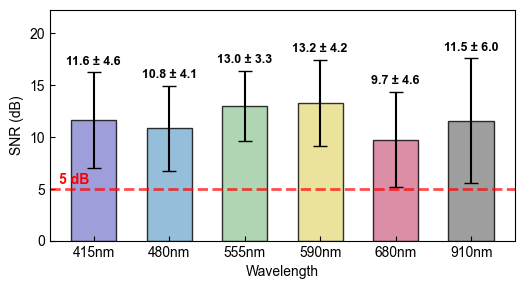


SNR Summary by Channel:
Channel    Mean±Std (dB)    Min (dB)    Max (dB)
--------------------------------------------------
415nm       11.6± 4.6         2.9        16.7
480nm       10.8± 4.1         4.5        17.6
555nm       13.0± 3.3         9.0        17.6
590nm       13.2± 4.2         6.5        19.3
680nm        9.7± 4.6         1.7        16.1
910nm       11.5± 6.0         0.0        18.0

Best performing channel: 590nm (13.2±4.2 dB)
Worst performing channel: 680nm (9.7±4.6 dB)


In [8]:
# Bar plot showing SNR for six channels with error bars
# Calculate mean and standard deviation across all regions for each channel

# Extract SNR data for each channel across all regions
channel_snrs = []
wavelengths_bar = ['415nm', '480nm', '555nm', '590nm', '680nm', '910nm']

for ch in range(6):
    channel_data = snr_matrix[:, ch]  # All regions for this channel
    channel_snrs.append(channel_data)

# Calculate statistics
means = [np.mean(data) for data in channel_snrs]
stds = [np.std(data) for data in channel_snrs]

# Create bar plot
fig, ax = plt.subplots(figsize=(6, 3))

bars = ax.bar(wavelengths_bar, means, yerr=stds, capsize=5, width=0.6, 
              color=colors, alpha=0.8, edgecolor='black', linewidth=1)

# Customize the plot
ax.set_xlabel('Wavelength')
ax.set_ylabel('SNR (dB)')
ax.tick_params(direction='in')

# Add value labels on top of bars
for i, (bar, mean, std) in enumerate(zip(bars, means, stds)):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + std + 0.5,
            f'{mean:.1f} ± {std:.1f}', ha='center', va='bottom', 
            fontsize=9, fontweight='bold')

# Set y-axis limits with some padding
ax.set_ylim(0, max(means) + max(stds) + 3)

# Add horizontal line at overall mean
overall_mean = np.mean(snr_matrix)
ax.axhline(y=5, color='red', linestyle='--', alpha=0.7, linewidth=2)
ax.text(0.02, 5.5, f'5 dB', 
        transform=ax.get_yaxis_transform(), fontsize=10, color='red', fontweight='bold')

ax.set_position(pos_ax)
# plt.savefig('../figures/SI/snr/snr_bar_plot.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

# Print summary statistics
print("\nSNR Summary by Channel:")
print("=" * 50)
print("Channel    Mean±Std (dB)    Min (dB)    Max (dB)")
print("-" * 50)
for i, wl in enumerate(wavelengths_bar):
    data = channel_snrs[i]
    print(f"{wl:8s}   {np.mean(data):5.1f}±{np.std(data):4.1f}      {np.min(data):6.1f}      {np.max(data):6.1f}")

print(f"\nBest performing channel: {wavelengths_bar[np.argmax(means)]} ({max(means):.1f}±{stds[np.argmax(means)]:.1f} dB)")
print(f"Worst performing channel: {wavelengths_bar[np.argmin(means)]} ({min(means):.1f}±{stds[np.argmin(means)]:.1f} dB)")